# 07 — Forecast comparison and dashboard export

This final notebook compares simple forecasting approaches on the same monthly total: a persistence baseline (next month equals the last observed month), a seasonal-naive baseline (use the same month in 2025), and the simple linear and polynomial regression outputs. It also exports route-month records for the frontend GUI.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

ROOT = Path.cwd()
data = pd.read_csv(ROOT / "data/processed/air_passenger_monthly.csv", parse_dates=["DATE"])
totals = data.groupby("DATE", as_index=False).PASSENGERS.sum().sort_values("DATE").reset_index(drop=True)
totals["TIME"] = np.arange(len(totals))
train = totals[totals.DATE.dt.year.eq(2025)].copy()
test = totals[totals.DATE.dt.year.eq(2026)].copy()
print(f"Training: {len(train)} months; holdout: {len(test)} months (2026 year-to-date)")

Training: 12 months; holdout: 7 months (2026 year-to-date)


## Compare like-for-like predictions
For each 2026 month, the seasonal-naive estimate uses the matching month in 2025. The persistence estimate uses the last observed month of 2025. Linear and degree-2 polynomial regression are trained on 2025 only. All scores are calculated against the same 2026 monthly totals.

In [2]:
linear = LinearRegression().fit(train[["TIME"]], np.log1p(train.PASSENGERS))
poly = make_pipeline(PolynomialFeatures(2, include_bias=False), LinearRegression())
poly.fit(train[["TIME"]], np.log1p(train.PASSENGERS))

predictions = pd.DataFrame({"DATE": test.DATE, "Actual": test.PASSENGERS})
predictions["Persistence"] = train.PASSENGERS.iloc[-1]
predictions["Seasonal naive"] = predictions.DATE.dt.month.map(train.set_index(train.DATE.dt.month).PASSENGERS)
predictions["Linear trend"] = np.expm1(linear.predict(test[["TIME"]]))
predictions["Polynomial trend"] = np.expm1(poly.predict(test[["TIME"]]))
predictions = predictions.replace([np.inf, -np.inf], np.nan).dropna()

rows = []
for name in predictions.columns.drop(["DATE", "Actual"]):
    rows.append({"Model": name,
                 "MAE": mean_absolute_error(predictions.Actual, predictions[name]),
                 "RMSE": mean_squared_error(predictions.Actual, predictions[name]) ** .5})
scores = pd.DataFrame(rows).sort_values("MAE")
display(scores)
display(predictions)

              Model           MAE          RMSE
1    Seasonal naive  1.497835e+06  1.901615e+06
0       Persistence  7.078207e+06  8.672295e+06
2      Linear trend  8.469895e+06  1.103249e+07
3  Polynomial trend  2.920610e+07  3.562962e+07
         DATE       Actual  ...  Linear trend  Polynomial trend
12 2026-01-01   79645464.0  ...  9.675823e+07      8.064337e+07
13 2026-02-01   76884283.0  ...  9.758619e+07      7.477433e+07
14 2026-03-01   93999761.0  ...  9.842123e+07      6.850461e+07
15 2026-04-01   90450847.0  ...  9.926342e+07      6.201123e+07
16 2026-05-01   95323217.0  ...  1.001128e+08      5.546312e+07
17 2026-06-01   97745648.0  ...  1.009695e+08      4.901416e+07
18 2026-07-01  101606380.0  ...  1.018335e+08      4.279787e+07

[7 rows x 6 columns]


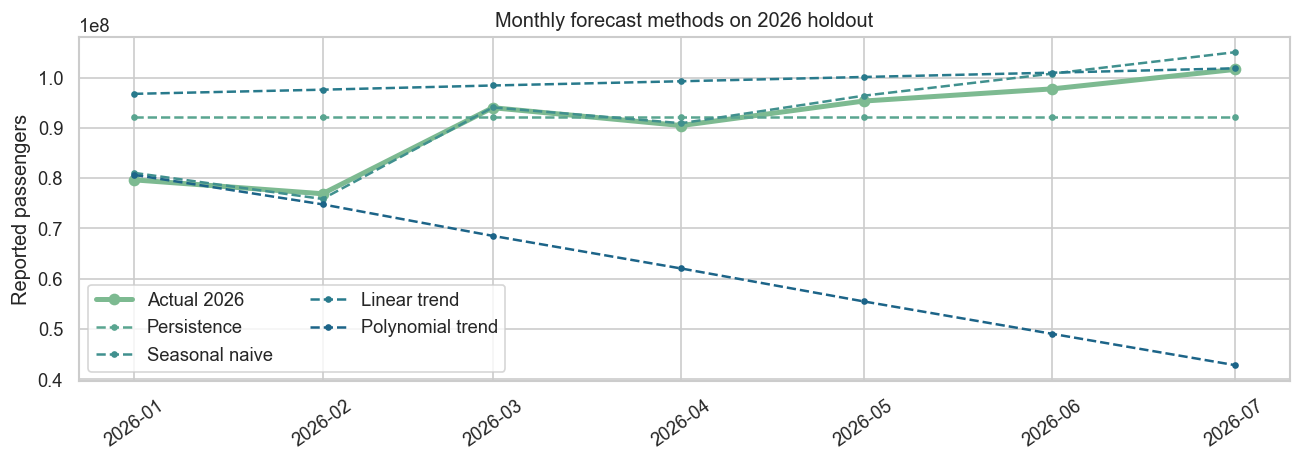

In [3]:
plt.figure(figsize=(11, 4))
plt.plot(predictions.DATE, predictions.Actual, marker="o", linewidth=3, label="Actual 2026")
for name in predictions.columns.drop(["DATE", "Actual"]):
    plt.plot(predictions.DATE, predictions[name], marker=".", linestyle="--", label=name)
plt.title("Monthly forecast methods on 2026 holdout")
plt.ylabel("Reported passengers")
plt.xlabel("")
plt.legend(ncol=2)
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

## Export data for the GUI
The dashboard accepts the cleaned route-airline-month CSV. This summary also gives a compact monthly series for simple charting and reporting.

In [4]:
dashboard = data[["DATE", "YEAR", "MONTH", "ORIGIN", "DEST",
                    "UNIQUE_CARRIER", "UNIQUE_CARRIER_NAME", "PASSENGERS", "DISTANCE"]].copy()
dashboard.to_csv(ROOT / "data/processed/dashboard_route_month.csv", index=False)
monthly_totals = totals[["DATE", "PASSENGERS"]].copy()
monthly_totals.to_csv(ROOT / "data/processed/dashboard_monthly_totals.csv", index=False)
print("Dashboard files exported:")
print(" - data/processed/dashboard_route_month.csv")
print(" - data/processed/dashboard_monthly_totals.csv")
print("Exported records:", f"{len(dashboard):,}")

Dashboard files exported:
 - data/processed/dashboard_route_month.csv
 - data/processed/dashboard_monthly_totals.csv
Exported records: 503,224


### Final report checklist
- Identify the source and exact downloaded years/months.
- State that 2026 is year-to-date and not a complete year.
- Report row counts before and after cleaning.
- Explain encoding, model features, and the chronological split.
- Compare models using the same target and holdout window.
- Mention limits: only one complete training year, no named passengers, no live flight status, and forecasts can change as BTS revises or adds months.
